<a href="https://colab.research.google.com/github/nishapandey9098/medical-image-classifier-ablation-study/blob/main/Project1_Ablation_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: How Much Does It Really Help?
### A multi-seed ablation study of pretraining, augmentation and CLAHE for small medical image classifiers

**Who this is for:** complete beginners. You do **not** need to understand every line of code. You **do** need to run the cells in order (top to bottom) and read the short explanations above each one.

**What you will build:** a small, honest research study. You will train the same neural network (a ResNet-18) many times with different settings and ask one question:

> Do ImageNet pretraining, data augmentation and CLAHE contrast enhancement *really* improve results on small medical image classifiers, or are the differences just random luck?

**Two datasets (both tiny, public and free, from the MedMNIST collection):**
- **PneumoniaMNIST**: chest X-rays, 2 classes (normal vs pneumonia)
- **RetinaMNIST**: retinal fundus photos, 5 classes (diabetic retinopathy severity 0 to 4)

**Time:** about 5 minutes for the quick test, about 1 hour for the full run (it runs by itself while you wait).

## Before you start (2 minutes)

1. You are probably reading this in **Google Colab**. If not: go to colab.research.google.com, then *File, Upload notebook*.
2. Turn on the free GPU: **Runtime, Change runtime type, T4 GPU, Save.** A GPU makes training many times faster (hours become minutes).
3. Run each cell with **Shift + Enter**, from top to bottom. Wait for a cell to finish before running the next one. Do not skip cells.
4. The first time, keep `QUICK_TEST = True` (a tiny trial run). When it works, you switch it to `False` for the real experiment.
5. If you see red error text, don't panic. Copy the **last 10 lines** of the error and paste them to Claude in your chat.

## Five ideas you need (read once, 5 minutes)

1. **Train / validation / test = practice exam / mock exam / final exam.** The model *learns* from the training images. We use the validation images to *choose* things (for example which training epoch is best). We look at the test images only at the very end, to get an honest score. If you choose settings by looking at the test score, your result is inflated. This is called **leakage**.
2. **Random seed.** Neural networks start from random numbers. A *seed* fixes those numbers. Two different seeds can give clearly different scores for the *same* settings. So one run proves almost nothing, and we repeat every setting with several seeds.
3. **Ablation.** Like baking: change one ingredient at a time (pretraining on/off, augmentation on/off, CLAHE on/off) and see if the cake really changes.
4. **Confidence interval (CI).** A range around an average that shows how uncertain it is. For an *effect* (a difference), if the 95% CI does not include 0, the effect is probably real. If it includes 0, you cannot tell.
5. **Scores.** *Accuracy* = share of correct answers (misleading when one class is much more common). *AUC* = how well the model ranks sick above healthy (1.0 perfect, 0.5 coin flip). *Macro-F1* = F1 averaged over classes. *QWK (quadratic weighted kappa)* = agreement that punishes big grading mistakes more than small ones (0 = chance, 1 = perfect); it is the standard score for diabetic retinopathy grading.

**The three ingredients we test**
- **Pretraining:** start from a network that already learned from ImageNet (over a million everyday photos) instead of from random numbers.
- **Augmentation:** each epoch, show the model slightly flipped, rotated, shifted, brighter or darker copies of the training images.
- **CLAHE:** a contrast filter that makes local details clearer. Widely used on retinal images and X-rays.

## Step 1: Set up

Cell 1a installs the MedMNIST library. Cell 1b loads the libraries. Cell 1c holds the **settings** (you will change `QUICK_TEST` later). Cell 1d connects Google Drive so your results are saved even if Colab disconnects (a pop-up will ask for permission: click *Allow*).

In [ ]:
# 1a. Install the MedMNIST library (it downloads the small datasets for us). Takes about 30 seconds.
!pip install -q medmnist

In [ ]:
# 1b. Load the libraries we need.
import os, time, math, random, hashlib, itertools, json, platform, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import scipy
import sklearn
from scipy import stats
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, cohen_kappa_score
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models

import medmnist
from medmnist import INFO, PneumoniaMNIST, RetinaMNIST

print("Libraries loaded. PyTorch", torch.__version__)

Libraries loaded. PyTorch 2.14.1+cu130


In [ ]:
# 1c. SETTINGS (you can change these)
QUICK_TEST = False    # True  = tiny trial run (about 5 minutes) just to check that everything works.
                        # False = the REAL experiment (about 1 hour). Switch to False only after the quick test works.
IMG_SIZE   = 64         # image size in pixels: 28, 64, 128 or 224. 64 is fast. Try 128 later if you have time.
N_SEEDS    = 5          # how many different random seeds for every setting
EPOCHS     = {"pneumoniamnist": 15, "retinamnist": 30}   # how many times the model sees the whole training set
BATCH_SIZE = 64         # how many images the model looks at per learning step
LR         = 3e-4       # learning rate: how big each learning step is
WEIGHT_DECAY = 1e-4     # a small penalty that stops the weights from growing too large

if QUICK_TEST:
    N_SEEDS = 2
    EPOCHS = {"pneumoniamnist": 2, "retinamnist": 2}

RUN_NAME = "quick_test" if QUICK_TEST else f"full_{IMG_SIZE}px"

DATASETS = {"pneumoniamnist": PneumoniaMNIST, "retinamnist": RetinaMNIST}
N_CLASSES = {flag: len(INFO[flag]["label"]) for flag in DATASETS}
PRIMARY = {"pneumoniamnist": "auc", "retinamnist": "qwk"}   # the main score we report for each dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Mode:", "QUICK TEST" if QUICK_TEST else "FULL EXPERIMENT", "| image size:", IMG_SIZE, "| seeds:", N_SEEDS)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU FOUND")
if device.type == "cpu":
    print("WARNING: no GPU found. Go to Runtime > Change runtime type > T4 GPU, then run again from the top.")

Mode: FULL EXPERIMENT | image size: 64 | seeds: 5
Device: cuda | Tesla T4


In [ ]:
# 1d. Where to save results. On Colab we use Google Drive so nothing is lost if Colab disconnects.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/ML_Project1_Ablation"
except Exception as e:
    print("Google Drive not used (" + type(e).__name__ + "). Saving in a local folder instead.")
    BASE_DIR = "./ML_Project1_Ablation"

OUT_DIR = os.path.join(BASE_DIR, RUN_NAME)
for sub in ["", "figures", "predictions", "models"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
print("Results will be saved in:", OUT_DIR)

# Write down exactly what software and settings were used (good research habit: reproducibility).
env = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__, "opencv": cv2.__version__, "medmnist": getattr(medmnist, "__version__", "unknown"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
    "img_size": IMG_SIZE, "n_seeds": N_SEEDS, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "learning_rate": LR, "weight_decay": WEIGHT_DECAY,
}
with open(os.path.join(OUT_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))

Mounted at /content/drive
Results will be saved in: /content/drive/MyDrive/ML_Project1_Ablation/full_64px
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "opencv": "4.14.0",
  "medmnist": "3.0.2",
  "gpu": "Tesla T4",
  "img_size": 64,
  "n_seeds": 5,
  "epochs": {
    "pneumoniamnist": 15,
    "retinamnist": 30
  },
  "batch_size": 64,
  "learning_rate": 0.0003,
  "weight_decay": 0.0001
}


## Step 2: Download the data and look at it

**Always look at your data before training.** This cell downloads both datasets (small files) and prints how many images each split has, and how many images each class has.

**What you should see:** PneumoniaMNIST with 2 classes and RetinaMNIST with 5 classes, and classes that are **not** equally common. (That imbalance is exactly why accuracy alone can mislead.) Write these numbers down: you will need them in your README.

If a download fails, just run the cell again.

In [ ]:
def load_dataset(flag):
    """Download one dataset and return {'train': (images, labels), 'val': ..., 'test': ...} as numpy arrays."""
    DataClass = DATASETS[flag]
    data = {}
    for split in ["train", "val", "test"]:
        ds = DataClass(split=split, download=True, size=IMG_SIZE)
        X = ds.imgs
        if X.ndim == 4 and X.shape[-1] == 1:          # grey images sometimes come with a useless last axis
            X = X[..., 0]
        data[split] = (X, ds.labels.reshape(-1).astype(np.int64))
    return data

raw = {flag: load_dataset(flag) for flag in DATASETS}

for flag in DATASETS:
    print(f"\n{flag}  | classes: {INFO[flag]['label']}")
    for split in ["train", "val", "test"]:
        X, y = raw[flag][split]
        per_class = np.bincount(y, minlength=N_CLASSES[flag]).tolist()
        print(f"  {split:5s}: images {X.shape}, images per class {per_class}")

100%|██████████| 20.6M/20.6M [00:10<00:00, 1.92MB/s]
100%|██████████| 13.2M/13.2M [00:19<00:00, 687kB/s]



pneumoniamnist  | classes: {'0': 'normal', '1': 'pneumonia'}
  train: images (4708, 64, 64), images per class [1214, 3494]
  val  : images (524, 64, 64), images per class [135, 389]
  test : images (624, 64, 64), images per class [234, 390]

retinamnist  | classes: {'0': '0', '1': '1', '2': '2', '3': '3', '4': '4'}
  train: images (1080, 64, 64, 3), images per class [486, 128, 206, 194, 66]
  val  : images (120, 64, 64, 3), images per class [54, 12, 28, 20, 6]
  test : images (400, 64, 64, 3), images per class [174, 46, 92, 68, 20]


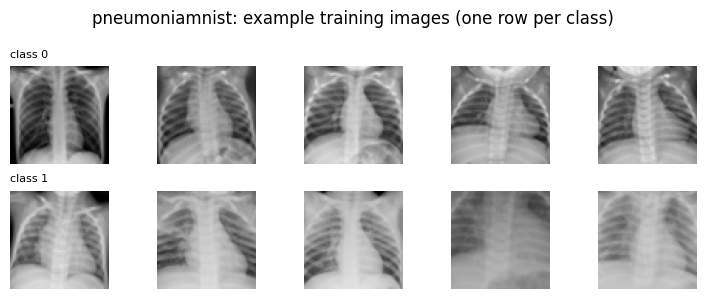

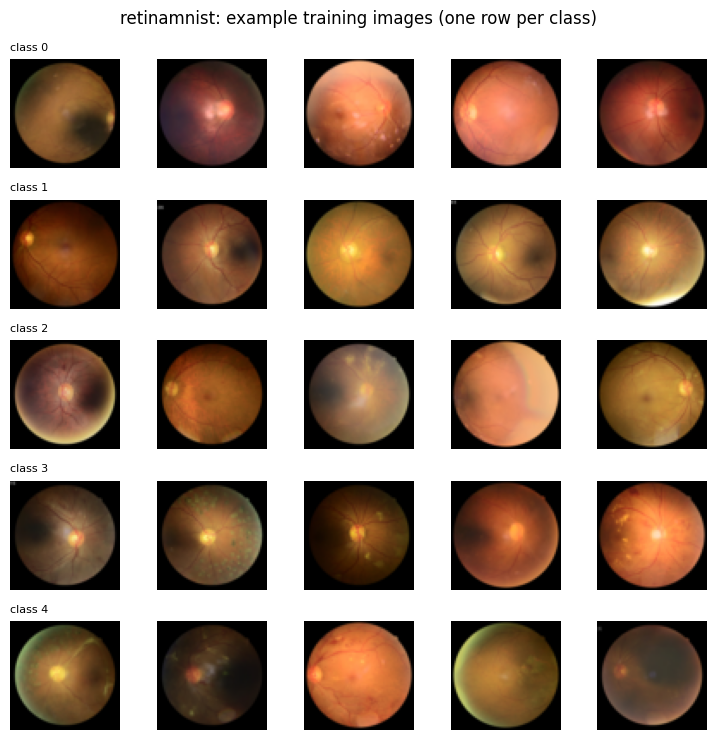

In [ ]:
def show_examples(flag, per_class=5):
    X, y = raw[flag]["train"]
    n_cls = N_CLASSES[flag]
    fig, axes = plt.subplots(n_cls, per_class, figsize=(per_class * 1.5, n_cls * 1.5), squeeze=False)
    for c in range(n_cls):
        idx = np.where(y == c)[0][:per_class]
        for j in range(per_class):
            ax = axes[c][j]
            ax.axis("off")
            if j < len(idx):
                img = X[idx[j]]
                if img.ndim == 2:
                    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
                else:
                    ax.imshow(img)
        axes[c][0].set_title(f"class {c}", fontsize=8, loc="left")
    fig.suptitle(f"{flag}: example training images (one row per class)")
    plt.tight_layout()
    plt.show()

for flag in DATASETS:
    show_examples(flag)

## Step 3: Check the data for leakage

**Leakage** means information from the test set sneaks into training, which makes results look better than they are. One simple form: the *same image* appears in both the training set and the test set. This cell fingerprints every image (an "MD5 hash") and counts identical images between the splits.

**What you want to see:** `0` identical images between splits. If a number is above 0, write it in your README and ask Claude how to remove those images.

**Limits of this check (say this in your README, it makes you look careful, not weak):** it only finds *exact* copies, not near-copies, and MedMNIST gives no patient IDs, so we cannot verify that all images of one patient stay inside one split.

In [ ]:
def image_hashes(X):
    return [hashlib.md5(img.tobytes()).hexdigest() for img in X]

for flag in DATASETS:
    hashes = {s: image_hashes(raw[flag][s][0]) for s in ["train", "val", "test"]}
    print(f"\n{flag}")
    for s in ["train", "val", "test"]:
        print(f"  {s:5s}: {len(hashes[s])} images, {len(set(hashes[s]))} unique")
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        shared = set(hashes[a]) & set(hashes[b])
        print(f"  identical images in both {a} and {b}: {len(shared)}")


pneumoniamnist
  train: 4708 images, 4690 unique
  val  : 524 images, 524 unique
  test : 624 images, 621 unique
  identical images in both train and val: 8
  identical images in both train and test: 0
  identical images in both val and test: 0

retinamnist
  train: 1080 images, 1080 unique
  val  : 120 images, 120 unique
  test : 400 images, 400 unique
  identical images in both train and val: 0
  identical images in both train and test: 0
  identical images in both val and test: 0


## Step 4: CLAHE and data preparation

**CLAHE** (Contrast Limited Adaptive Histogram Equalization) improves *local* contrast. We apply it with the same settings to **all** splits (train, validation and test) when the CLAHE ingredient is switched on. For colour retina photos we apply it only to the lightness channel, so colours are not distorted. For grey X-rays we apply it directly.

The helper `get_data` prepares each version of each dataset once (with or without CLAHE) and remembers it, so later runs are fast. All images are turned into 3-channel pictures, because ResNet-18 expects 3 channels.

**What you should see:** a row of original images and a row of CLAHE images below it. CLAHE images should look a bit "punchier" in local detail.

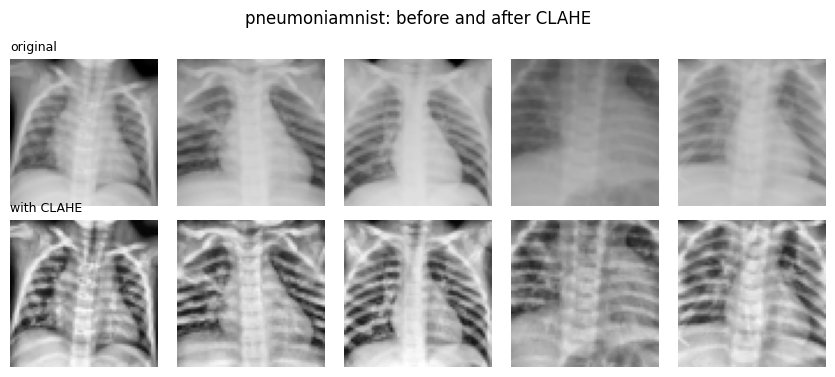

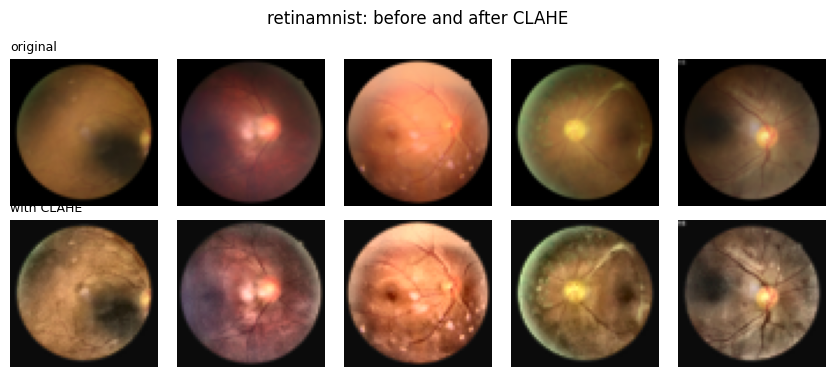

In [ ]:
def apply_clahe(X, clip_limit=2.0, tile_grid=(8, 8)):
    """Apply CLAHE to every image in X (uint8 array)."""
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    out = np.empty_like(X)
    for i in range(len(X)):
        img = np.ascontiguousarray(X[i])
        if img.ndim == 2:                                   # grey image (chest X-ray)
            out[i] = clahe.apply(img)
        else:                                               # colour image (retina)
            lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
            lightness = np.ascontiguousarray(lab[:, :, 0])
            lab[:, :, 0] = clahe.apply(lightness)
            out[i] = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return out

def to_rgb_array(X):
    """(N,H,W) grey or (N,H,W,3) colour -> (N,3,H,W): the layout PyTorch expects, always with 3 channels."""
    if X.ndim == 3:
        X = np.repeat(X[:, :, :, None], 3, axis=3)
    return np.ascontiguousarray(X.transpose(0, 3, 1, 2))

_PREPARED = {}
def get_data(flag, use_clahe):
    """Return {'train': (images, labels), 'val': ..., 'test': ...} as PyTorch tensors (remembered after first use)."""
    key = (flag, bool(use_clahe))
    if key not in _PREPARED:
        out = {}
        for split in ["train", "val", "test"]:
            X, y = raw[flag][split]
            if use_clahe:
                X = apply_clahe(X)
            out[split] = (torch.from_numpy(to_rgb_array(X)), torch.from_numpy(y))
        _PREPARED[key] = out
    return _PREPARED[key]

def show_clahe_examples(flag, n=5):
    X, y = raw[flag]["train"]
    X = X[:n]
    Xc = apply_clahe(X)
    fig, axes = plt.subplots(2, n, figsize=(n * 1.7, 3.8), squeeze=False)
    for j in range(n):
        for r, arr in enumerate([X[j], Xc[j]]):
            ax = axes[r][j]
            ax.axis("off")
            if arr.ndim == 2:
                ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
            else:
                ax.imshow(arr)
    axes[0][0].set_title("original", fontsize=9, loc="left")
    axes[1][0].set_title("with CLAHE", fontsize=9, loc="left")
    fig.suptitle(f"{flag}: before and after CLAHE")
    plt.tight_layout()
    plt.show()

for flag in DATASETS:
    show_clahe_examples(flag)

## Step 5: The model, the training loop and the scores

You do **not** need to understand every line. What matters:

- `augment_batch`: randomly flips, rotates (up to 10 degrees), shifts (up to 5%) and changes brightness and contrast (up to 20%) of every training image. It is used only when "augmentation" is switched on, and only on **training** images.
- `build_model`: a **ResNet-18** (a standard, small image network). `pretrained=True` starts from ImageNet weights, `False` starts from random numbers. The last layer is replaced to match our number of classes.
- `train_one_run`: trains **one** model with one setting and one seed. After every epoch it measures the loss on the **validation** set and remembers the best epoch. At the end it loads that best epoch and scores it on validation and test, **once**.
- `metrics_from_proba`: accuracy, macro-F1, QWK and AUC.
- `majority_baseline`: a "dumb" model that always answers the most common class. Any real model must beat it. It also shows why accuracy alone can fool you.

All runs use the **same** learning rate, batch size and epochs, so that only the three ingredients change. (Limitation: each setting might work even better with its own tuning. Mention this in your README.)

In [ ]:
def set_seed(seed):
    """Fix all random number generators so a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)   # ImageNet averages
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def normalize(x):
    """x: float images in [0,1], shape (B,3,H,W)."""
    return (x - MEAN) / STD

def augment_batch(x, max_rot_deg=10, max_shift=0.05, brightness=0.2, contrast=0.2):
    """Random flip, small rotation, small shift, brightness and contrast change. Every image gets its own random values."""
    B = x.shape[0]
    dev = x.device
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)                       # random left-right flip
    angle = (torch.rand(B, device=dev) * 2 - 1) * max_rot_deg * math.pi / 180.0
    tx = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    ty = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos, -sin, tx], dim=1),
                         torch.stack([sin, cos, ty], dim=1)], dim=1)           # one 2x3 matrix per image
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)   # rotate + shift
    b = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * brightness
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * contrast
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - mean) * c + mean) * b                                            # contrast, then brightness
    return x.clamp(0, 1)

def build_model(n_classes, pretrained):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model.to(device)

@torch.no_grad()
def predict_logits(model, X_uint8, batch_size=256):
    """Raw model outputs for all images in X_uint8 (a CPU uint8 tensor). Returns a CPU tensor."""
    model.eval()
    chunks = []
    for i in range(0, len(X_uint8), batch_size):
        xb = X_uint8[i:i + batch_size].to(device).float() / 255.0
        chunks.append(model(normalize(xb)).float().cpu())
    return torch.cat(chunks)

In [ ]:
def metrics_from_proba(proba, y, n_classes):
    """proba: (N, n_classes) predicted probabilities, y: true labels. Returns a dict of scores."""
    proba = np.asarray(proba, dtype=np.float64)
    proba = proba / proba.sum(axis=1, keepdims=True)
    y = np.asarray(y)
    pred = proba.argmax(axis=1)
    out = {
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "qwk": cohen_kappa_score(y, pred, weights="quadratic"),
    }
    try:
        if n_classes == 2:
            out["auc"] = roc_auc_score(y, proba[:, 1])
        else:
            out["auc"] = roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=list(range(n_classes)))
    except ValueError:
        out["auc"] = float("nan")
    return out

def compute_metrics(logits, y, n_classes):
    proba = torch.softmax(logits, dim=1).numpy()
    return metrics_from_proba(proba, y.numpy(), n_classes)

def majority_baseline(flag):
    """Scores of a dumb model that always predicts the most common training class."""
    y_train = raw[flag]["train"][1]
    y_test = raw[flag]["test"][1]
    majority = int(np.bincount(y_train).argmax())
    proba = np.zeros((len(y_test), N_CLASSES[flag]))
    proba[:, majority] = 1.0
    return majority, metrics_from_proba(proba, y_test, N_CLASSES[flag])

def config_name(pretrained, augment, clahe):
    parts = ["pretrained" if pretrained else "scratch"]
    if augment:
        parts.append("aug")
    if clahe:
        parts.append("clahe")
    return "+".join(parts)

def build_record(flag, pretrained, augment, clahe, seed, best_epoch, best_val_loss, seconds, val_metrics, test_metrics):
    """One row of the results table."""
    rec = {"dataset": flag, "config": config_name(pretrained, augment, clahe),
           "pretrained": int(pretrained), "augment": int(augment), "clahe": int(clahe),
           "seed": seed, "best_epoch": best_epoch, "val_loss": best_val_loss, "train_seconds": round(seconds, 1)}
    for k, v in val_metrics.items():
        rec["val_" + k] = v
    for k, v in test_metrics.items():
        rec["test_" + k] = v
    return rec

for flag in DATASETS:
    majority, base = majority_baseline(flag)
    print(f"{flag}: a dumb model that always says 'class {majority}' gets "
          f"accuracy {base['accuracy']:.3f}, AUC {base['auc']:.3f}, QWK {base['qwk']:.3f} on the test set.")

pneumoniamnist: a dumb model that always says 'class 1' gets accuracy 0.625, AUC 0.500, QWK 0.000 on the test set.
retinamnist: a dumb model that always says 'class 0' gets accuracy 0.435, AUC 0.500, QWK 0.000 on the test set.


In [ ]:
def train_one_run(flag, pretrained, augment, clahe, seed, epochs, verbose=False, weights_path=None, save_outputs=False):
    """Train ONE model with ONE setting and ONE seed. Returns (record, history)."""
    set_seed(seed)
    n_classes = N_CLASSES[flag]
    data = get_data(flag, clahe)
    X_train, y_train = data["train"]
    X_val, y_val = data["val"]
    X_test, y_test = data["test"]
    X_train_dev, y_train_dev = X_train.to(device), y_train.to(device)
    n_train = len(y_train)

    model = build_model(n_classes, pretrained)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    shuffler = torch.Generator().manual_seed(seed)          # decides the order of the training images

    best_val_loss, best_epoch, best_state = float("inf"), 0, None
    history = []
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(n_train, generator=shuffler).to(device)
        running_loss = torch.zeros((), device=device)
        for i in range(0, n_train, BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            if len(idx) < 2:
                continue
            xb = X_train_dev[idx].float() / 255.0
            yb = y_train_dev[idx]
            if augment:
                xb = augment_batch(xb)
            loss = F.cross_entropy(model(normalize(xb)), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            running_loss += loss.detach() * len(idx)
        scheduler.step()

        val_logits = predict_logits(model, X_val)
        val_loss = F.cross_entropy(val_logits, y_val).item()
        train_loss = running_loss.item() / n_train
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        if val_loss < best_val_loss or best_state is None:          # best epoch so far, chosen on VALIDATION data only
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  epoch {epoch:2d}/{epochs} | training loss {train_loss:.3f} | validation loss {val_loss:.3f}")

    model.load_state_dict(best_state)                                # go back to the best epoch
    val_logits = predict_logits(model, X_val)
    test_logits = predict_logits(model, X_test)                      # the test set is used ONCE, here
    record = build_record(flag, pretrained, augment, clahe, seed, best_epoch, best_val_loss, time.time() - start,
                          compute_metrics(val_logits, y_val, n_classes), compute_metrics(test_logits, y_test, n_classes))

    if save_outputs:                                                 # keep the predictions for Projects 2 to 4
        np.savez_compressed(os.path.join(OUT_DIR, "predictions", f"{flag}__{record['config']}__seed{seed}.npz"),
                            val_logits=val_logits.numpy(), test_logits=test_logits.numpy())
    if weights_path is not None:
        torch.save(best_state, weights_path)

    del model, optimizer, X_train_dev, y_train_dev
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return record, history

print("Training code is ready.")

Training code is ready.


## Step 6: Try ONE run first (about 30 seconds)

Before launching dozens of runs, train a single model for 5 epochs and look at what happens.

**What you should see:**
- The **training loss** goes down every epoch (the model is learning).
- The **validation loss** usually goes down too, then flattens or rises. The epoch with the lowest validation loss (dotted line) is the one we keep. When training loss keeps falling but validation loss rises, that is **overfitting**: the model memorizes the training images.
- Test scores for PneumoniaMNIST: AUC is usually around 0.9 or higher. If your AUC is around 0.5 (a coin flip), something is wrong.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


  epoch  1/5 | training loss 0.189 | validation loss 0.292
  epoch  2/5 | training loss 0.097 | validation loss 0.093
  epoch  3/5 | training loss 0.069 | validation loss 0.082
  epoch  4/5 | training loss 0.052 | validation loss 0.071
  epoch  5/5 | training loss 0.045 | validation loss 0.066

Result of this single run (on the TEST set):
  accuracy : 0.923
  macro_f1 : 0.914
  qwk      : 0.830
  auc      : 0.985
  chosen epoch: 5 | time: 16.2 seconds


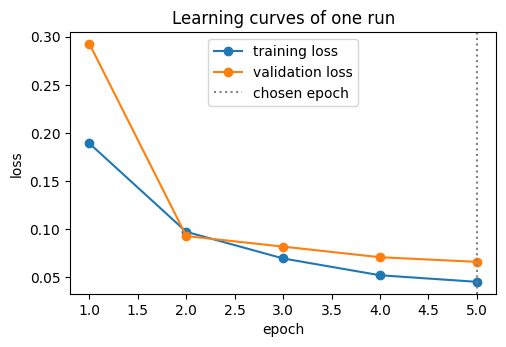

In [ ]:
record, history = train_one_run("pneumoniamnist", pretrained=True, augment=True, clahe=False, seed=0, epochs=5, verbose=True)

print("\nResult of this single run (on the TEST set):")
for m in ["accuracy", "macro_f1", "qwk", "auc"]:
    print(f"  {m:9s}: {record['test_' + m]:.3f}")
print(f"  chosen epoch: {record['best_epoch']} | time: {record['train_seconds']} seconds")

hist = pd.DataFrame(history)
plt.figure(figsize=(5.5, 3.4))
plt.plot(hist["epoch"], hist["train_loss"], marker="o", label="training loss")
plt.plot(hist["epoch"], hist["val_loss"], marker="o", label="validation loss")
plt.axvline(record["best_epoch"], color="gray", ls=":", label="chosen epoch")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Learning curves of one run")
plt.legend()
plt.show()

## Step 7: The full experiment (it runs by itself)

This cell trains **8 settings x N seeds x 2 datasets**, one model after another. The 8 settings are every combination of pretraining (on/off), augmentation (on/off) and CLAHE (on/off), named like `pretrained+aug+clahe` or `scratch`.

- **Quick test** (`QUICK_TEST = True`): 2 seeds, 2 epochs: 32 runs, about 5 minutes. Its results go into a separate folder called `quick_test`, so they never mix with your real results.
- **Full run** (`QUICK_TEST = False`): 5 seeds: 80 runs, about **1 hour** on a free GPU (30 to 90 minutes depending on the GPU Colab gives you).

**How to switch from quick test to the real run:** go back to cell 1c, change `QUICK_TEST = True` to `QUICK_TEST = False`, then click **Runtime, Run all**. (Colab re-runs everything from the top; it stops if a cell has an error.)

**Good to know**
- After **every** run, one line is added to `results.csv` on your Drive.
- If Colab disconnects, reconnect and click **Runtime, Run all** again. The loop **skips runs that are already finished** and continues where it stopped.
- Keep this browser tab open and your computer awake and plugged in.
- In the quick test there are only 2 seeds, so every confidence interval will be huge. That is normal. The quick test only checks that the code runs; ignore its numbers.
- Each output line shows the main test score of that run. Do not try to judge anything from single lines. That is the whole point of this study.

In [ ]:
RESULTS_CSV = os.path.join(OUT_DIR, "results.csv")
configs = [dict(pretrained=p, augment=a, clahe=c) for p, a, c in itertools.product([0, 1], repeat=3)]
jobs = [(flag, cfg, seed) for seed in range(N_SEEDS) for flag in DATASETS for cfg in configs]

done = set()
if os.path.exists(RESULTS_CSV):
    old = pd.read_csv(RESULTS_CSV)
    done = set(zip(old["dataset"], old["config"], old["seed"]))

todo = [(flag, cfg, seed) for (flag, cfg, seed) in jobs
        if (flag, config_name(**cfg), seed) not in done]
print(f"Planned runs: {len(jobs)} | already finished: {len(jobs) - len(todo)} | to do now: {len(todo)}\n")

t_start = time.time()
for k, (flag, cfg, seed) in enumerate(todo, start=1):
    record, _ = train_one_run(flag, bool(cfg["pretrained"]), bool(cfg["augment"]), bool(cfg["clahe"]),
                              seed, EPOCHS[flag], save_outputs=True)
    pd.DataFrame([record]).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
    minutes_left = (len(todo) - k) * (time.time() - t_start) / k / 60
    main_score = record["test_" + PRIMARY[flag]]
    print(f"[{k:2d}/{len(todo)}] {flag:15s} {record['config']:22s} seed {seed} | "
          f"test {PRIMARY[flag].upper()} {main_score:.3f} | best epoch {record['best_epoch']:2d} | "
          f"{record['train_seconds']:5.0f}s | about {minutes_left:.0f} min left")

print("\nAll runs finished. Results are in:", RESULTS_CSV)

Planned runs: 80 | already finished: 0 | to do now: 80

[ 1/80] pneumoniamnist  scratch                seed 0 | test AUC 0.948 | best epoch  9 |    30s | about 39 min left
[ 2/80] pneumoniamnist  scratch+clahe          seed 0 | test AUC 0.953 | best epoch  8 |    31s | about 40 min left
[ 3/80] pneumoniamnist  scratch+aug            seed 0 | test AUC 0.972 | best epoch 11 |    32s | about 40 min left
[ 4/80] pneumoniamnist  scratch+aug+clahe      seed 0 | test AUC 0.977 | best epoch 13 |    33s | about 40 min left
[ 5/80] pneumoniamnist  pretrained             seed 0 | test AUC 0.958 | best epoch  3 |    32s | about 40 min left
[ 6/80] pneumoniamnist  pretrained+clahe       seed 0 | test AUC 0.980 | best epoch  4 |    32s | about 39 min left
[ 7/80] pneumoniamnist  pretrained+aug         seed 0 | test AUC 0.985 | best epoch 12 |    32s | about 39 min left
[ 8/80] pneumoniamnist  pretrained+aug+clahe   seed 0 | test AUC 0.987 | best epoch 11 |    32s | about 38 min left
[ 9/80] retinamn

## Step 8: Read the results

This step loads `results.csv` and builds three things for each dataset:

1. **A score table**: for each of the 8 settings, the average main score over the seeds (`mean`), its 95% confidence interval (`ci95_half_width`: the true average is probably within plus or minus this value), the standard deviation (`std`), and the lowest and highest seed.
2. **An "effects" table**: the answer to your research question. For every seed we compute *(average score of the 4 settings with the ingredient ON) minus (average of the 4 settings with it OFF)*. Then we average over the seeds and compute a 95% CI. CI entirely above 0: **clear improvement**. Entirely below 0: **clear decrease**. Includes 0: **cannot tell**.
3. **"Seed luck"**: how much the *same* setting changes just by changing the seed. Differences between settings that are smaller than this are not trustworthy.

Main scores: **AUC** for PneumoniaMNIST and **QWK** for RetinaMNIST. The dumb baseline is printed so you can see how much the models really add.

*Statistics note:* we compare 3 ingredients per dataset. With several comparisons, an occasional "clear" result can still be a fluke, so treat borderline cases with care and say so in your README.

In [ ]:
df = pd.read_csv(RESULTS_CSV)
print(f"Loaded {len(df)} finished runs. Seeds per dataset:", df.groupby("dataset")["seed"].nunique().to_dict())

def mean_ci(values, level=0.95):
    """Average and half-width of the confidence interval (t-distribution, suitable for few seeds)."""
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    n = len(v)
    if n == 0:
        return np.nan, np.nan
    if n == 1:
        return float(v[0]), np.nan
    half = stats.t.ppf((1 + level) / 2, df=n - 1) * v.std(ddof=1) / np.sqrt(n)
    return float(v.mean()), float(half)

def summary_table(flag):
    d = df[df["dataset"] == flag]
    metric = "test_" + PRIMARY[flag]
    rows = []
    for name, g in d.groupby("config"):
        m, h = mean_ci(g[metric])
        rows.append({"config": name, "runs": len(g), "mean": m, "ci95_half_width": h,
                     "std": g[metric].std(ddof=1), "min": g[metric].min(), "max": g[metric].max()})
    return pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)

def factor_effects(flag, metric):
    d = df[df["dataset"] == flag]
    rows = []
    for factor in ["pretrained", "augment", "clahe"]:
        per_seed = []
        for s, ds in d.groupby("seed"):
            if len(ds) < 8:                      # only use seeds where all 8 settings finished
                continue
            on = ds.loc[ds[factor] == 1, metric].mean()
            off = ds.loc[ds[factor] == 0, metric].mean()
            per_seed.append(on - off)
        m, h = mean_ci(per_seed)
        if np.isnan(h):
            verdict = "need at least 2 complete seeds"
        elif m - h > 0:
            verdict = "clear improvement"
        elif m + h < 0:
            verdict = "clear decrease"
        else:
            verdict = "cannot tell (CI includes 0)"
        rows.append({"ingredient": factor, "effect": m, "ci95_half_width": h,
                     "ci_low": m - h, "ci_high": m + h, "seeds_used": len(per_seed), "verdict": verdict})
    return pd.DataFrame(rows)

for flag in DATASETS:
    metric = PRIMARY[flag]
    print("=" * 78)
    print(f"{flag.upper()}  |  main score: test {metric.upper()}")
    majority, base = majority_baseline(flag)
    print(f"Dumb baseline (always class {majority}): accuracy {base['accuracy']:.3f}, AUC {base['auc']:.3f}, QWK {base['qwk']:.3f}")

    table = summary_table(flag)
    print("\nScore of each setting (mean over seeds):")
    display(table.round(3))
    table.to_csv(os.path.join(OUT_DIR, f"summary_{flag}.csv"), index=False)

    spread = table["max"] - table["min"]
    print(f"Seed luck: for the SAME setting, the best and worst seed differ by {spread.mean():.3f} on average "
          f"({spread.max():.3f} at most).")

    effects = factor_effects(flag, "test_" + metric)
    print(f"\nEffect of each ingredient on test {metric.upper()} (ON minus OFF, averaged over the other ingredients):")
    display(effects.round(3))
    effects.to_csv(os.path.join(OUT_DIR, f"effects_{flag}.csv"), index=False)

Loaded 80 finished runs. Seeds per dataset: {'pneumoniamnist': 5, 'retinamnist': 5}
PNEUMONIAMNIST  |  main score: test AUC
Dumb baseline (always class 1): accuracy 0.625, AUC 0.500, QWK 0.000

Score of each setting (mean over seeds):


,config,runs,mean,ci95_half_width,std,min,max
0,pretrained+aug+clahe,5,0.985,0.007,0.006,0.975,0.987
1,pretrained+aug,5,0.984,0.006,0.005,0.975,0.989
2,pretrained+clahe,5,0.977,0.006,0.004,0.969,0.980
3,scratch+aug+clahe,5,0.972,0.007,0.006,0.962,0.977
4,pretrained,5,0.970,0.014,0.011,0.958,0.984
5,scratch+aug,5,0.965,0.009,0.007,0.954,0.972
6,scratch+clahe,5,0.961,0.008,0.007,0.953,0.971
7,scratch,5,0.951,0.007,0.006,0.942,0.956


Seed luck: for the SAME setting, the best and worst seed differ by 0.016 on average (0.026 at most).

Effect of each ingredient on test AUC (ON minus OFF, averaged over the other ingredients):


,ingredient,effect,ci95_half_width,ci_low,ci_high,seeds_used,verdict
0,pretrained,0.016,0.006,0.011,0.022,5,clear improvement
1,augment,0.012,0.006,0.005,0.018,5,clear improvement
2,clahe,0.006,0.003,0.003,0.009,5,clear improvement


RETINAMNIST  |  main score: test QWK
Dumb baseline (always class 0): accuracy 0.435, AUC 0.500, QWK 0.000

Score of each setting (mean over seeds):


,config,runs,mean,ci95_half_width,std,min,max
0,pretrained+aug+clahe,5,0.579,0.054,0.043,0.515,0.623
1,pretrained+aug,5,0.552,0.077,0.062,0.451,0.618
2,pretrained+clahe,5,0.537,0.044,0.036,0.512,0.599
3,scratch+aug,5,0.519,0.063,0.051,0.474,0.607
4,pretrained,5,0.498,0.063,0.051,0.434,0.561
5,scratch+aug+clahe,5,0.429,0.079,0.063,0.383,0.539
6,scratch,5,0.303,0.246,0.198,0.008,0.502
7,scratch+clahe,5,0.201,0.128,0.103,0.044,0.330


Seed luck: for the SAME setting, the best and worst seed differ by 0.195 on average (0.495 at most).

Effect of each ingredient on test QWK (ON minus OFF, averaged over the other ingredients):


,ingredient,effect,ci95_half_width,ci_low,ci_high,seeds_used,verdict
0,pretrained,0.179,0.124,0.055,0.302,5,clear improvement
1,augment,0.135,0.092,0.043,0.227,5,clear improvement
2,clahe,-0.031,0.053,-0.084,0.021,5,cannot tell (CI includes 0)


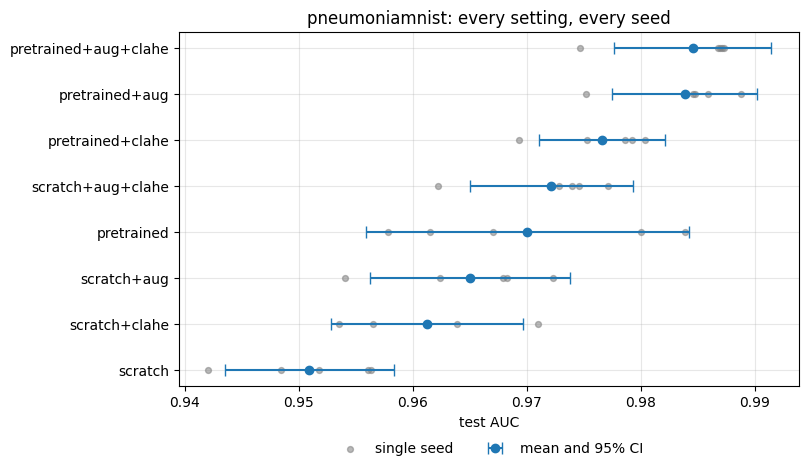

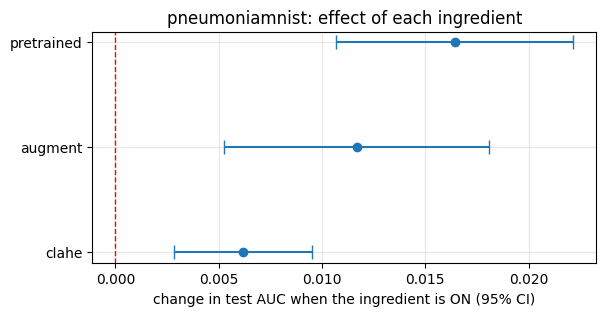

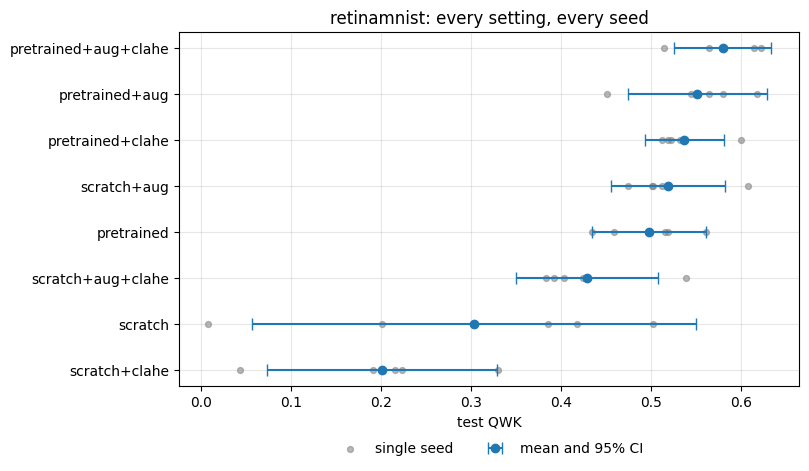

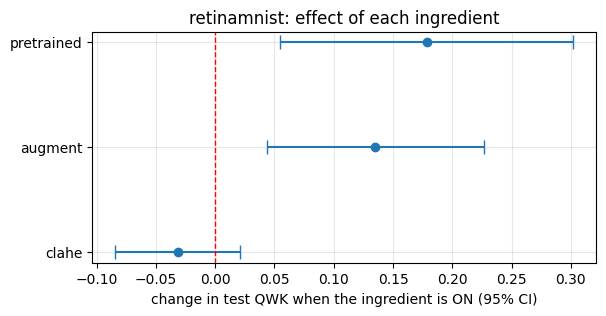

Figures saved in: /content/drive/MyDrive/ML_Project1_Ablation/full_64px/figures


In [ ]:
def plot_config_scores(flag):
    d = df[df["dataset"] == flag]
    metric = "test_" + PRIMARY[flag]
    table = summary_table(flag).sort_values("mean").reset_index(drop=True)      # best setting ends up at the top
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for i, name in enumerate(table["config"]):
        seed_values = d.loc[d["config"] == name, metric].values
        ax.scatter(seed_values, np.full(len(seed_values), i), s=18, color="gray", alpha=0.55, zorder=2,
                   label="single seed" if i == 0 else None)
    ax.errorbar(table["mean"], np.arange(len(table)), xerr=table["ci95_half_width"], fmt="o", color="C0",
                capsize=4, zorder=3, label="mean and 95% CI")
    ax.set_yticks(np.arange(len(table)))
    ax.set_yticklabels(table["config"])
    ax.set_xlabel(f"test {PRIMARY[flag].upper()}")
    ax.set_title(f"{flag}: every setting, every seed")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    fig.savefig(os.path.join(OUT_DIR, "figures", f"{flag}_config_scores.png"), dpi=150, bbox_inches="tight")
    plt.show()

def plot_effects(flag):
    eff = factor_effects(flag, "test_" + PRIMARY[flag])
    fig, ax = plt.subplots(figsize=(6.5, 3.0))
    y = np.arange(len(eff))
    ax.errorbar(eff["effect"], y, xerr=eff["ci95_half_width"], fmt="o", capsize=5)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(eff["ingredient"])
    ax.invert_yaxis()                      # first ingredient at the top
    ax.set_xlabel(f"change in test {PRIMARY[flag].upper()} when the ingredient is ON (95% CI)")
    ax.set_title(f"{flag}: effect of each ingredient")
    ax.grid(alpha=0.3)
    fig.savefig(os.path.join(OUT_DIR, "figures", f"{flag}_effects.png"), dpi=150, bbox_inches="tight")
    plt.show()

for flag in DATASETS:
    plot_config_scores(flag)
    plot_effects(flag)
print("Figures saved in:", os.path.join(OUT_DIR, "figures"))

## Step 9: Save one reference model per dataset (for Projects 2, 3 and 4)

Later projects (calibration, compression, testing) need a trained model. We pick the best setting for each dataset using the **validation** score, **not** the test score. (Choosing by test score would be a small form of leakage.) Then we retrain it once with seed 0 and save its weights and predictions in the `models` folder on your Drive.

The files in `models` and `predictions` are **not** for GitHub. Keep them on Drive.

In [ ]:
reference = {}
for flag in DATASETS:
    d = df[df["dataset"] == flag]
    val_col = "val_" + PRIMARY[flag]
    best_name = d.groupby("config")[val_col].mean().idxmax()
    row = d[d["config"] == best_name].iloc[0]
    reference[flag] = {"config": best_name, "pretrained": bool(row["pretrained"]),
                       "augment": bool(row["augment"]), "clahe": bool(row["clahe"])}
    print(f"{flag}: best setting by validation {PRIMARY[flag].upper()} = {best_name}")

for flag, r in reference.items():
    path = os.path.join(OUT_DIR, "models", f"reference_{flag}.pt")
    rec, _ = train_one_run(flag, r["pretrained"], r["augment"], r["clahe"], seed=0, epochs=EPOCHS[flag],
                           save_outputs=True, weights_path=path)
    r["test_" + PRIMARY[flag]] = rec["test_" + PRIMARY[flag]]
    print(f"saved {path}  (test {PRIMARY[flag].upper()} of this retrained model: {r['test_' + PRIMARY[flag]]:.3f})")

with open(os.path.join(OUT_DIR, "reference_models.json"), "w") as f:
    json.dump(reference, f, indent=2)

pneumoniamnist: best setting by validation AUC = pretrained+aug
retinamnist: best setting by validation QWK = pretrained+aug+clahe
saved /content/drive/MyDrive/ML_Project1_Ablation/full_64px/models/reference_pneumoniamnist.pt  (test AUC of this retrained model: 0.985)
saved /content/drive/MyDrive/ML_Project1_Ablation/full_64px/models/reference_retinamnist.pt  (test QWK of this retrained model: 0.564)


## Step 10: Package everything for GitHub

This cell writes `results_tables.md` (tables ready to paste into your README) and creates `github_upload.zip` with the small files you should upload: the results, summary tables, figures and environment file. It will also start a download of the zip file in Colab.

In [ ]:
def df_to_markdown(d):
    cols = list(d.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in d.iterrows():
        cells = [f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

def readme_table(flag):
    d = df[df["dataset"] == flag]
    order = summary_table(flag)["config"].tolist()
    rows = []
    for name in order:
        g = d[d["config"] == name]
        row = {"setting": name, "seeds": len(g)}
        for m in ["accuracy", "macro_f1", "qwk", "auc"]:
            mean, half = mean_ci(g["test_" + m])
            row[m] = f"{mean:.3f} ± {half:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

parts = ["# Results tables (auto-generated)\n",
         f"Run: `{RUN_NAME}`. Values are mean ± 95% CI over seeds, on the TEST set.\n"]
for flag in DATASETS:
    majority, base = majority_baseline(flag)
    parts.append(f"\n## {flag}\n")
    parts.append(f"Dumb baseline (always predict class {majority}): accuracy {base['accuracy']:.3f}, "
                 f"AUC {base['auc']:.3f}, QWK {base['qwk']:.3f}\n")
    parts.append("\n### All scores per setting\n")
    parts.append(df_to_markdown(readme_table(flag)))
    parts.append(f"\n\n### Effect of each ingredient on test {PRIMARY[flag].upper()} (ON minus OFF)\n")
    parts.append(df_to_markdown(factor_effects(flag, "test_" + PRIMARY[flag]).round(3)))
    parts.append("\n")
with open(os.path.join(OUT_DIR, "results_tables.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(parts))
print("Wrote results_tables.md")

export_dir = os.path.join(OUT_DIR, "github_upload")
os.makedirs(export_dir, exist_ok=True)
small_files = ["results.csv", "results_tables.md", "environment.json"] + \
              [f for f in os.listdir(OUT_DIR) if f.startswith(("summary_", "effects_")) and f.endswith(".csv")]
for fname in small_files:
    shutil.copy(os.path.join(OUT_DIR, fname), export_dir)
shutil.copytree(os.path.join(OUT_DIR, "figures"), os.path.join(export_dir, "figures"), dirs_exist_ok=True)
zip_path = shutil.make_archive(os.path.join(OUT_DIR, "github_upload"), "zip", export_dir)
print("Created:", zip_path)

if QUICK_TEST:
    print("\nNOTE: this was only the QUICK TEST. Do NOT upload these results. Set QUICK_TEST = False and run everything again.")
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("(Not in Colab: find the zip file at the path above.)")

Wrote results_tables.md
Created: /content/drive/MyDrive/ML_Project1_Ablation/full_64px/github_upload.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### 11a. How to read your results (write these sentences in your own words)
- **Is the model better than the dumb baseline?** Compare your best rows with the baseline numbers printed in Step 8.
- **Which ingredient matters?** Look at the "effects" tables. If the CI excludes 0 ("clear improvement"), say so with the numbers: *"Pretraining changed test AUC by +0.0xx (95% CI 0.0xx to 0.0xx)."* If it says "cannot tell", say **that**: *"No clear effect of CLAHE at 64x64 (CI includes 0)."* A "no effect" result is a valid finding as long as you report it honestly.
- **How big is seed noise?** Use the "seed luck" line. Differences smaller than that should not be claimed.
- **Do ingredients interact?** Look at the score table: for example CLAHE might help only when training from scratch, not with pretraining. Mention it if you see it.
- **Do the two datasets agree?** If an ingredient helps one dataset but not the other, say so.

**Never write a number in your README or CV that you did not get from your own run.**

### 11b. Put it on GitHub (no command line needed)
1. Go to github.com and sign in (create a free account if you need one; pick a professional username, because it goes on your CV).
2. Click **+, New repository**. Name: `medical-image-ablation-study`. Choose **Public**, tick **Add a README file**, click **Create repository**.
3. Re-run this notebook with `QUICK_TEST = False` (Runtime, Run all). When it is done, download it with outputs: **File, Download, Download .ipynb**. (Outputs make your plots visible on GitHub without anyone running the code.)
4. On your computer, unzip `github_upload.zip`. In the repository click **Add file, Upload files** and drag in: the notebook, `requirements.txt`, and the unzipped files and the `figures` folder. Click **Commit changes**.
5. Open `README.md` in the repository, click the pencil icon, paste your finished README text, click **Commit changes**.
6. Do **not** upload the `models` or `predictions` folders. They stay on your Drive for Projects 2 to 4.
7. Put the repository link in the **GitHub** field of your CV header and in the project entry. On your GitHub profile, pin the repository.



## Troubleshooting

| Problem | What to do |
|---|---|
| `NO GPU FOUND` | Runtime, Change runtime type, T4 GPU, Save. Then Runtime, Run all. If Colab says no GPU is available, try again later, or use a Kaggle notebook (also free GPU; turn "Internet" on in its settings). |
| `ModuleNotFoundError: medmnist` | Run cell 1a again. If Colab asks you to restart the session, restart and then run all cells from the top. |
| Download error in Step 2 | Run the cell again (the server is sometimes slow). |
| `CUDA out of memory` | Set `BATCH_SIZE = 32` (and keep `IMG_SIZE = 64`), then Runtime, Restart session, Run all. |
| Colab disconnected during Step 7 | Reconnect and click Runtime, Run all. Finished runs are skipped automatically. |